# Lab 01 — Anatomy of Real Cosmological Data

**Theory for lab:** https://docs.google.com/document/d/1Dqw43Us2Pc1lf3UKccTO8aKjvR2T9H6g/edit

**Lecture notes:** https://docs.google.com/document/d/1XV-566XS44idqtAmQyGSfxOZXCOmvsb5/edit

**Course:** MSc Astrostatistics for Observational Cosmology  
**Format:** 4-hour hands-on practical  
**Status:** Formative + weekly checkpoint  
**Real data:** Pantheon+ / SH0ES and SDSS Reverberation Mapping (SDSS-RM)

> ## Scientific question
> **What was actually measured, what was derived, and where does uncertainty enter before we do any cosmological inference?**

This first lab is deliberately about **data literacy before model fitting**. You will work with two real observational datasets:

1. a Type-Ia-supernova Hubble-diagram product from Pantheon+ / SH0ES;
2. continuum and broad-line light-curve products from SDSS-RM.

You will **not fit cosmological parameters today**.

---

## Learning outcomes

By the end of the lab you should be able to:

- distinguish a physical source from a catalogue row;
- distinguish measured, derived, calibration and model quantities;
- identify units, flags, missing values and repeated observations;
- understand why a published uncertainty column may be valid for plotting but not for inference;
- inspect an irregular AGN light curve without touching a spectrum;
- state a statistical question in terms of an **estimand**, **observations**, assumptions and validation.

## 0. Before coding — the five-line statement

Write one sentence for each item **before running the scientific analysis**.

1. **Estimand:** What quantity would you eventually like to infer?
2. **Observed data:** Which quantities were measured or reported?
3. **Generative assumptions:** What physical/statistical chain might connect the estimand to the observations?
4. **Uncertainty / selection:** What could distort that connection?
5. **Validation:** What observation or diagnostic could make you distrust the analysis?

### Your answer

**Estimand:** We are not estimating any cosmological parameters in this lab. We are exploring the statistical properties of the datasets.

**Observed data:** We have from Supernova: redshifts, magnitude, and unvertainties. For the AGN we have the flux measurements at different observation times. 

**Generative assumptions:** We receive this information from photons that travel from this objects to our telescopes. After this it is processes and we create the catalogues. 

**Uncertainty / selection:** If we have measurement uncertainties and different calibrations could affect the observational data. 

**Validation:** If we see missing values or we see differences between different surveys. 

## 1. Setup

Run the next cell. The notebook uses only standard scientific-Python packages plus `astroquery` for the SDSS-RM part.

If you are using Google Colab and `astroquery` is missing, run:

```python
!pip -q install astroquery
```

In [10]:
!pip -q install astroquery

In [1]:
from pathlib import Path
import io, sys, warnings, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from astropy.cosmology import FlatLambdaCDM

SEED = 2026
rng = np.random.default_rng(SEED) # It allow us to sample and freeze the sample. We use this to get reproducible texts

pd.set_option("display.max_columns", 60) 
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Matplotlib is building the font cache; this may take a moment.


Python: 3.14.6
NumPy: 2.4.6
Pandas: 3.0.3


# Part I — Pantheon+ / SH0ES

## 2. Download a real public data product

We use the published file `Pantheon+SH0ES.dat`.

Important terminology from the data release:

- `CID`: candidate/SN identifier;
- `IDSURVEY`: survey identifier;
- `zHD`: Hubble-diagram redshift;
- `m_b_corr`: corrected/standardized \(m_B\);
- `m_b_corr_err_DIAG`: diagonal uncertainty for visualization;
- `MU_SH0ES`: standardized distance modulus using the SH0ES Cepheid calibration;
- `MU_SH0ES_ERR_DIAG`: diagonal uncertainty for visualization;
- `IS_CALIBRATOR`: whether the SN host has a Cepheid distance.

**Critical warning from the Pantheon+ release:** the diagonal uncertainty columns are for plotting/visualization. Cosmological inference requires the released covariance matrix. We will exploit that distinction later in the course.

In [2]:
PANTHEON_URL = (
    "https://raw.githubusercontent.com/PantheonPlusSH0ES/DataRelease/main/"
    "Pantheon%2B_Data/4_DISTANCES_AND_COVAR/Pantheon%2BSH0ES.dat"
)

def load_pantheon(url=PANTHEON_URL):
    """Download the published Pantheon+SH0ES high-level table."""
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    return pd.read_csv(io.StringIO(r.text), sep=r"\s+")

sn = load_pantheon()
print(f"Rows: {len(sn):,}")
print(f"Unique CID values: {sn['CID'].nunique():,}")
display(sn.head())

Rows: 1,701
Unique CID values: 1,543


,CID,IDSURVEY,zHD,zHDERR,zCMB,zCMBERR,zHEL,zHELERR,m_b_corr,m_b_corr_err_DIAG,MU_SH0ES,MU_SH0ES_ERR_DIAG,CEPH_DIST,IS_CALIBRATOR,USED_IN_SH0ES_HF,c,cERR,x1,x1ERR,mB,mBERR,x0,x0ERR,COV_x1_c,COV_x1_x0,COV_c_x0,RA,DEC,HOST_RA,HOST_DEC,HOST_ANGSEP,VPEC,VPECERR,MWEBV,HOST_LOGMASS,HOST_LOGMASS_ERR,PKMJD,PKMJDERR,NDOF,FITCHI2,FITPROB,m_b_corr_err_RAW,m_b_corr_err_VPEC,biasCor_m_b,biasCorErr_m_b,biasCor_m_b_COVSCALE,biasCor_m_b_COVADD
0,2011fe,51,0.00122,0.00084,0.00122,0.00002,0.00082,0.00002,9.74571,1.516210,28.9987,1.516450,29.1770,1,0,-0.107600,0.040080,-0.548188,0.133730,9.58436,0.032722,2.63181,0.079318,0.000114,-0.000525,-0.002728,210.774,54.2737,-999,-999,-9.0,0.0,250,0.007589,10.67700,-9.000,55815.0,0.1071,36,26.8859,0.864470,0.0991,1.4960,0.0381,0.005,1.0,0.003
1,2011fe,56,0.00122,0.00084,0.00122,0.00002,0.00082,0.00002,9.80286,1.517230,29.0559,1.517470,29.1770,1,0,-0.032895,0.038463,-0.380481,0.086100,9.78448,0.035244,2.18880,0.071051,-0.000444,-0.001502,-0.002201,210.774,54.2737,-999,-999,-9.0,0.0,250,0.007589,10.67700,0.000,55815.2,0.0579,101,88.3064,0.812220,0.0971,1.4960,-0.0252,0.003,1.0,0.004
2,2012cg,51,0.00256,0.00084,0.00256,0.00002,0.00144,0.00002,11.47030,0.781906,30.7233,0.782372,30.8433,1,0,0.100730,0.018231,0.491960,0.023545,11.81610,0.023712,0.33695,0.007359,-0.000061,0.000009,-0.000111,186.803,9.4203,-999,-999,-9.0,0.0,250,0.017772,9.63300,0.002,56082.4,0.0278,165,233.5000,0.000358,0.0399,0.7134,0.0545,0.019,1.0,0.036
3,2012cg,56,0.00256,0.00084,0.00256,0.00002,0.00144,0.00002,11.49190,0.798612,30.7449,0.799068,30.8433,1,0,0.122470,0.039030,0.712610,0.083554,11.88010,0.035961,0.31765,0.010521,0.000223,-0.000137,-0.000344,186.803,9.4203,-999,-999,-9.0,0.0,250,0.017772,9.63300,0.004,56082.4,0.0667,55,100.1220,0.000193,0.0931,0.7134,0.0622,0.028,1.0,0.040
4,1994DRichmond,50,0.00299,0.00084,0.00299,0.00004,0.00187,0.00004,11.52270,0.880798,30.7757,0.881212,-9.0000,0,0,-0.111684,0.026044,-1.618030,0.049543,11.53340,0.032255,0.43715,0.012987,-0.000099,-0.000035,-0.000291,188.510,7.7016,-999,-999,-9.0,0.0,250,0.019104,8.46247,-9.000,49432.6,0.0522,146,109.8390,0.988740,0.0567,0.6110,0.0650,0.009,1.0,0.006


## 3. First audit: never analyse a table you have not inspected

### Exercise 1

Without making a cosmological plot yet:

1. print the column names;
2. report the number of rows;
3. report the number of unique `CID` values;
4. find how many `CID`s occur more than once;
5. inspect the five most frequently repeated `CID`s;
6. check for non-finite values in `zHD`, `MU_SH0ES`, `m_b_corr`.

**Question:** Why can the number of catalogue rows exceed the number of physical SNe?
- We can have more rows becuase we may have more than one observation of the same object. 

In [14]:
# TODO: complete the audit.
print(sn.columns.tolist())

counts_per_cid = sn.groupby("CID").size().sort_values(ascending=False)

# TODO:
n_rows = len(sn)
n_unique = sn.nunique()
n_repeated_cids = (counts_per_cid > 1).sum() #Check if an SNe appears more that once and add them up 

display(counts_per_cid.head())

['CID', 'IDSURVEY', 'zHD', 'zHDERR', 'zCMB', 'zCMBERR', 'zHEL', 'zHELERR', 'm_b_corr', 'm_b_corr_err_DIAG', 'MU_SH0ES', 'MU_SH0ES_ERR_DIAG', 'CEPH_DIST', 'IS_CALIBRATOR', 'USED_IN_SH0ES_HF', 'c', 'cERR', 'x1', 'x1ERR', 'mB', 'mBERR', 'x0', 'x0ERR', 'COV_x1_c', 'COV_x1_x0', 'COV_c_x0', 'RA', 'DEC', 'HOST_RA', 'HOST_DEC', 'HOST_ANGSEP', 'VPEC', 'VPECERR', 'MWEBV', 'HOST_LOGMASS', 'HOST_LOGMASS_ERR', 'PKMJD', 'PKMJDERR', 'NDOF', 'FITCHI2', 'FITPROB', 'm_b_corr_err_RAW', 'm_b_corr_err_VPEC', 'biasCor_m_b', 'biasCorErr_m_b', 'biasCor_m_b_COVSCALE', 'biasCor_m_b_COVADD', 'SURVEY']


CID
2006ej    4
2007af    4
2003du    3
2007ca    3
2009D     3
dtype: int64

In [15]:
print("Number of rows:", n_rows)
print("Unique SNe:", n_unique)
print("Repeated CIDs:", n_repeated_cids)

Number of rows: 1701
Unique SNe: CID                     1543
IDSURVEY                  20
zHD                     1464
zHDERR                   141
zCMB                    1477
zCMBERR                   49
zHEL                    1328
zHELERR                   49
m_b_corr                1684
m_b_corr_err_DIAG       1695
MU_SH0ES                1684
MU_SH0ES_ERR_DIAG       1697
CEPH_DIST                 38
IS_CALIBRATOR              2
USED_IN_SH0ES_HF           2
c                       1696
cERR                    1659
x1                      1701
x1ERR                   1682
mB                      1686
mBERR                   1699
x0                      1701
x0ERR                   1700
COV_x1_c                1701
COV_x1_x0               1701
COV_c_x0                1701
RA                      1528
DEC                     1529
HOST_RA                    2
HOST_DEC                   2
HOST_ANGSEP              638
VPEC                    1502
VPECERR                    1
MWEBV     

### Interpretation box

Write 3–5 sentences. In particular, explain why treating every row as an independent physical SN can be dangerous in a resampling exercise.
Tje Pantheon+ catalogue contains more rows than a unique Supernova becuase some objects are observed multiple times. These observations are not necessarily independent sicne they belong to the same object. So if we treat them as independent objects the excercise will gie more weight to this repeated observations and ut will affect our results. So thats why its importnat to apply the unique part on the code. 

## 4. Survey composition

Pantheon+ combines multiple surveys. The release maps `IDSURVEY` values to survey names.

For this lab, use the following subset of the published mapping:

SURVEY
SDSS          321
PS1MD         269
DES           203
FOUND         179
SNLS          160
LOSS2         105
CSP            89
CFA3K          58
SOUSA          57
LOSS1          48
LOWZ/JRK07     46
CFA4p2         38
Name: count, dtype: int64

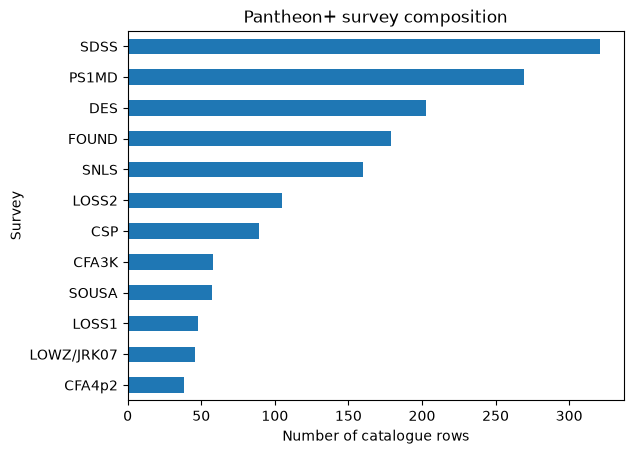

In [4]:
SURVEY_MAP = {
    1:"SDSS", 4:"SNLS", 5:"CSP", 10:"DES", 15:"PS1MD",
    18:"CNIa0.02", 50:"LOWZ/JRK07", 51:"LOSS1", 56:"SOUSA",
    57:"LOSS2", 61:"CFA1", 62:"CFA2", 63:"CFA3S", 64:"CFA3K",
    65:"CFA4p2", 66:"CFA4p3", 100:"HST", 101:"SNAP",
    106:"CANDELS", 150:"FOUND"
}
sn["SURVEY"] = sn["IDSURVEY"].map(SURVEY_MAP).fillna("OTHER")

survey_counts = sn["SURVEY"].value_counts()
display(survey_counts.head(12))

ax = survey_counts.head(12).sort_values().plot(kind="barh")
ax.set_xlabel("Number of catalogue rows")
ax.set_ylabel("Survey")
ax.set_title("Pantheon+ survey composition")
plt.show()

### Exercise 2

Answer:

**1. Is Pantheon+ a single homogeneous survey?** No, it contains observations from several astronomical surveys, that use different instruments and surveys. 

**2. Why might survey identity matter statistically even after standardization?** Even if standarization is applied, the surveys have different uncertainties or calibrations.

**3. Which later course topic is already visible here: independence, selection, covariance, domain shift, or all of them?** All of them are visible since we are combining observations. 

## 5. Redshift and uncertainty structure

Use `zHD` for the Hubble-diagram redshift.

For **visualization only**, inspect `MU_SH0ES_ERR_DIAG`.

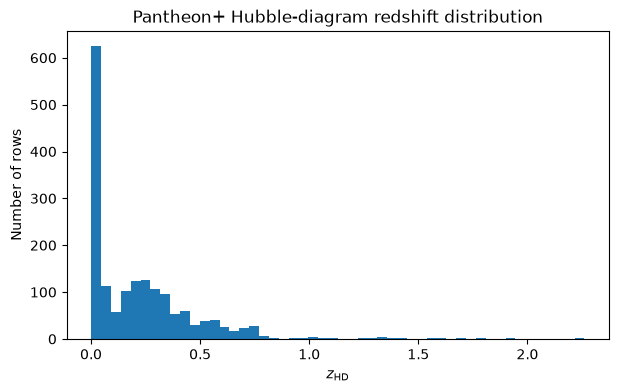

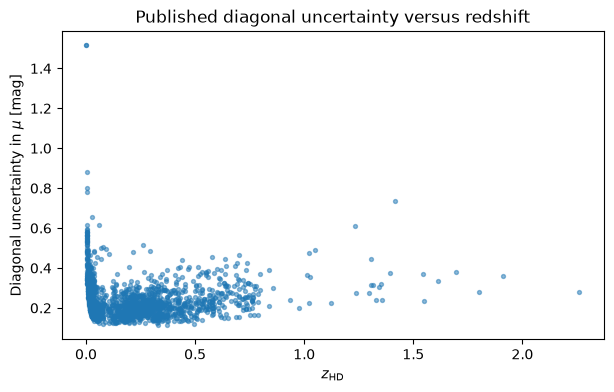

In [6]:
fig, ax = plt.subplots(figsize=(7,4))
ax.hist(sn["zHD"], bins=50)
ax.set_xlabel(r"$z_{\rm HD}$")
ax.set_ylabel("Number of rows")
ax.set_title("Pantheon+ Hubble-diagram redshift distribution")
plt.show()

fig, ax = plt.subplots(figsize=(7,4))
ax.scatter(sn["zHD"], sn["MU_SH0ES_ERR_DIAG"], s=8, alpha=0.5)
ax.set_xlabel(r"$z_{\rm HD}$")
ax.set_ylabel(r"Diagonal uncertainty in $\mu$ [mag]")
ax.set_title("Published diagonal uncertainty versus redshift")
plt.show()

### Exercise 3 — do not just describe the picture

Calculate for three redshift intervals:

\[
z<0.1,\qquad 0.1\le z<0.5,\qquad z\ge 0.5,
\]

the number of rows, median diagonal uncertainty, and MAD of the diagonal uncertainty.

Then answer:

> Does the measurement precision remain constant with redshift?

No it does not remain constant with redshift. The median uncertainty is lowest at intermidian redshifts and highest and large redshifts. 

Do **not** infer a causal explanation from this table alone.

In [7]:
bins = pd.cut(
    sn["zHD"],
    bins=[-np.inf, 0.1, 0.5, np.inf],
    labels=["z<0.1", "0.1<=z<0.5", "z>=0.5"]
)

def mad(x):
    x = np.asarray(x, float)
    med = np.nanmedian(x) #resistant to outlires more than mean 
    return np.nanmedian(np.abs(x-med))

summary = (
    sn.assign(zbin=bins)
      .groupby("zbin", observed=True)["MU_SH0ES_ERR_DIAG"]
      .agg(N="size", median="median", MAD=mad)
)
display(summary)

,N,median,MAD
zbin,,,
z<0.1,741,0.235009,0.054139
0.1<=z<0.5,750,0.201030,0.034879
z>=0.5,210,0.254278,0.051068


## 6. Observed, derived, calibrated or model quantity?

Complete this table in a Markdown cell.

| Quantity | Meaning | Directly observed? | Derived/calibrated? | Used as model parameter? |
|---|---|---|---|---|
| `zHEL` |Heliocentric redshift  |yes  |no  | no |
| `zHD` | Hubble-diagram redshift  | no |yes  | no |
| `mB` | apparent magnitude (B band) | no | yes | no |
| `m_b_corr` | corrected apparent magnitude | no | yes | no |
| `MU_SH0ES` | calibrated distance modulus | no | yes | no |
| \(H_0\) | Hubble constant | no | no | yes |
| \(\Omega_m\) | Matter density parameter | no | no | yes |

### Key question

Why is `MU_SH0ES` **not** simply a raw telescope measurement?
Is a derived quantity that is obtained from SNe measurements after applying standarization and calibration corrections. 


# Part II — SDSS Reverberation Mapping

## 7. Retrieve published SDSS-RM light-curve products

The VizieR catalogue `J/ApJ/851/21` contains:

- `table1`: 222 quasar records;
- `table2`: 152,258 continuum/emission-line measurements;
- `table4`: 44 H\(\beta\) reverberation-mapped objects;
- `table5`: 18 H\(\alpha\) reverberation-mapped objects.

The light-curve table contains bands `g`, `i`, `Halpha`, and `Hbeta`.

The published `MJD` field is **MJD − 50000**, so we restore the full MJD for plotting.

In [18]:
## I found a mistake in this code, there is no list 4 I think. 

#try:
#    from astroquery.vizier import Vizier
#except ImportError:
#   raise ImportError("Install astroquery first: pip install astroquery")

#Vizier.ROW_LIMIT = -1

#sample_tab = Vizier.get_catalogs("J/ApJ/851/21/table1")[0].to_pandas()
#lc_tab = Vizier.get_catalogs("J/ApJ/851/21/table2")[0].to_pandas()
#hb_tab = Vizier.get_catalogs("J/ApJ/851/21/table4")[0].to_pandas()

#for frame in (sample_tab, lc_tab, hb_tab):
#    for col in frame.select_dtypes(include=["object"]).columns:
#        frame[col] = frame[col].astype(str).str.strip()

#lc_tab["MJD_full"] = lc_tab["MJD"].astype(float) + 50000.0

#print("SDSS-RM sample rows:", len(sample_tab))
#print("SDSS-RM light-curve rows:", len(lc_tab))
#print("Published Hbeta-lag objects:", len(hb_tab))
#display(sample_tab.head())
#display(lc_tab.head())

In [17]:
try:
    from astroquery.vizier import Vizier
except ImportError:
    raise ImportError("Install astroquery first: pip install astroquery")

Vizier.ROW_LIMIT = -1

# Load SDSS-RM datasets
sample_tab = Vizier.get_catalogs("J/ApJ/851/21/table1")[0].to_pandas()
lc_tab = Vizier.get_catalogs("J/ApJ/851/21/table2")[0].to_pandas()
hb_tab = Vizier.get_catalogs("J/ApJ/851/21/results")[0].to_pandas()

# Clean string columns
for frame in (sample_tab, lc_tab, hb_tab):
    for col in frame.select_dtypes(include=["object", "str"]).columns:
        frame[col] = frame[col].astype(str).str.strip()

# Convert MJD
lc_tab["MJD_full"] = lc_tab["MJD"].astype(float) + 50000.0

# Print results
print("SDSS-RM sample rows:", len(sample_tab))
print("SDSS-RM light-curve rows:", len(lc_tab))
print("Published lag-result objects:", len(hb_tab))

display(sample_tab.head())
display(lc_tab.head())
display(hb_tab.head())

SDSS-RM sample rows: 222
SDSS-RM light-curve rows: 152258
Published lag-result objects: 62


,VP,RMID,Nf,SDSS,RAJ2000,DEJ2000,z,imag,SNR,logAGN,logHost,logM,RMCat,LCc,LCi,Sloan,SimbadName,NED
0,,5,256,J141541.41+530424.3,213.9225,53.0734,1.020,20.716000,5.0,44.500000,NaN,8.1,1,LCc,LCi,Sloan,SDSS J141541.40+530424.2,NED
1,,9,748,J141359.51+531049.3,213.4980,53.1804,0.898,20.473000,4.3,44.099998,43.799999,7.9,2,LCc,LCi,Sloan,SDSS J141359.51+531049.2,NED
2,*,16,691,J141606.95+530929.8,214.0290,53.1583,0.848,19.716000,11.5,44.799999,43.900002,9.0,2,LCc,LCi,Sloan,SDSS J141606.95+530929.7,NED
3,*,17,611,J141324.28+530527.0,213.3511,53.0908,0.456,19.212999,14.1,43.900002,44.200001,8.4,2,LCc,LCi,Sloan,SDSS J141324.27+530526.9,NED
4,,18,748,J141323.27+531034.3,213.3469,53.1762,0.849,20.205000,5.2,44.299999,44.200001,8.9,2,LCc,LCi,Sloan,SDSS J141323.26+531034.3,NED


,RMID,MJD,Band,Tel,Flux,e_Flux,S,e_S,Flag,MJD_full
0,5,6660.2090,g,S,16.990000,0.33,NaN,NaN,0,56660.2090
1,5,6664.5130,g,S,16.990000,0.33,NaN,NaN,0,56664.5130
2,5,6669.5003,g,S,16.900000,0.34,NaN,NaN,0,56669.5003
3,5,6686.4734,g,S,17.469999,0.35,NaN,NaN,0,56686.4734
4,5,6711.5226,g,C,17.480000,0.19,NaN,NaN,0,56711.5226


,Band,RMID,z,tau,e_tau,E_tau,Sig,e_Sig,rmsSig,e_rmsSig,FWHM,e_FWHM,rmsFWHM,e_rmsFWHM,VP,e_VP,E_VP,MBH,e_MBH,E_MBH,sig*,e_sig*
0,Hb,16,0.848,32.000000,15.5,11.6,4585,50,6477,54,7976,42,7859,112,26.200001,15.9,13.5,117.300003,71.199997,60.500000,NaN,NaN
1,Hb,17,0.456,25.500000,5.8,10.9,6937,14,6101,48,16318,30,7758,77,18.500000,8.0,10.4,82.800003,35.900002,46.599998,191.399994,3.700000
2,Hb,21,1.026,43.900002,4.3,4.9,4856,536,6543,34,7442,5983,11002,1743,36.599998,14.0,14.1,163.800003,62.500000,63.099998,NaN,NaN
3,Hb,33,0.715,26.500000,8.8,9.9,776,13,857,32,1070,30,1626,243,0.400000,0.2,0.2,1.700000,0.800000,0.900000,182.399994,21.700001
4,Hb,101,0.458,21.400000,6.4,4.2,1186,2,976,32,2220,9,2135,94,0.400000,0.2,0.2,1.800000,0.800000,0.700000,NaN,NaN


## 8. Inspect the data model

### Exercise 4

For `table2`, identify:

- object identifier;
- time;
- observed band;
- telescope;
- continuum flux and its unacertainty;
- integrated line flux and its uncertainty;
- rejection flag.

Then calculate how many rows belong to each `Band`.

**Question: Why is a random train/test split by rows invalid if we later build a machine-learning model of objects?**

If we split the rows randomly some of the objects would appear in the training and on the test set. This causes some issues.

In [19]:
display(lc_tab["Band"].value_counts())

# TODO:
# How many distinct RMID objects occur in the full light-curve table?
# How many observations does the median object have?

n_objects = lc_tab["RMID"].nunique()
median_obs = lc_tab.groupby("RMID").size().median()

print("Number of unique objects:", n_objects)
print("Median observations per object:", median_obs)

Band
g         75346
i         68160
Hbeta      7067
Halpha     1685
Name: count, dtype: int64

Number of unique objects: 222
Median observations per object: 632.5


## 9. Plot one real AGN without touching a spectrum

We choose the first object in the published H\(\beta\)-lag table. This is not because it is "best"; it simply guarantees that a published H\(\beta\) lag exists for later comparison.

Example RMID: 16
Redshift: 0.8479999899864197
g-band rows: 346 | Hbeta rows: 31


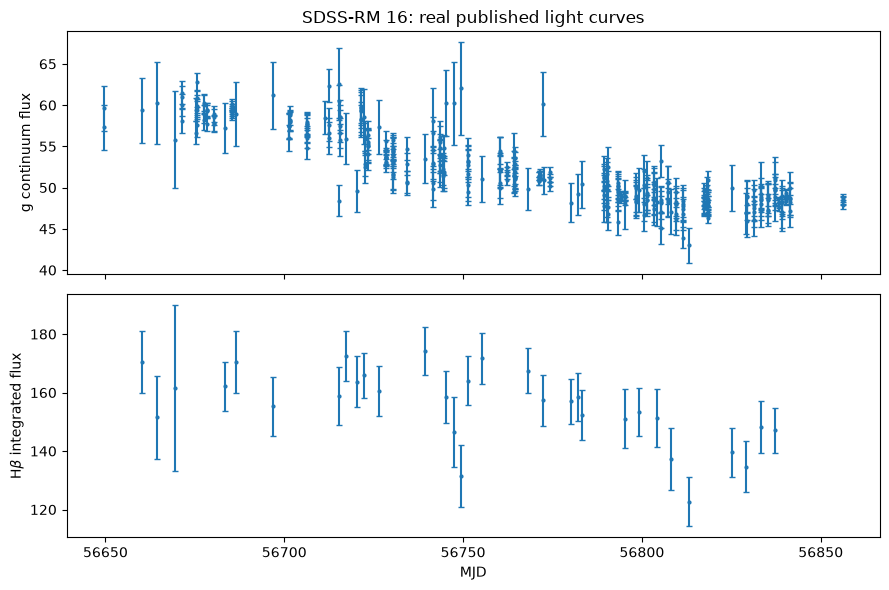

In [20]:
example_rmid = int(hb_tab.iloc[0]["RMID"])
obj = lc_tab[lc_tab["RMID"].astype(int) == example_rmid].copy()
z_obj = float(sample_tab.loc[sample_tab["RMID"].astype(int)==example_rmid, "z"].iloc[0])

g = obj[obj["Band"]=="g"].copy()
hb = obj[(obj["Band"]=="Hbeta") & (obj["Flag"].fillna(0).astype(int)==0)].copy()

print("Example RMID:", example_rmid)
print("Redshift:", z_obj)
print("g-band rows:", len(g), "| Hbeta rows:", len(hb))

fig, axes = plt.subplots(2,1, figsize=(9,6), sharex=True)

axes[0].errorbar(
    g["MJD_full"], g["Flux"], yerr=g["e_Flux"],
    fmt=".", ms=4, capsize=2
)
axes[0].set_ylabel("g continuum flux")
axes[0].set_title(f"SDSS-RM {example_rmid}: real published light curves")

axes[1].errorbar(
    hb["MJD_full"], hb["S"], yerr=hb["e_S"],
    fmt=".", ms=4, capsize=2
)
axes[1].set_xlabel("MJD")
axes[1].set_ylabel(r"H$\beta$ integrated flux")

plt.tight_layout()
plt.show()

## 10. Cadence is part of the data

For the \(g\)-band continuum and H\(\beta\) line separately, calculate:

- number of epochs;
- observing baseline;
- median separation between adjacent epochs;
- minimum and maximum separation.

### Why this matters

A lag is not inferred from \(C(t)\) and \(L(t)\) in the abstract. It is inferred from **irregularly sampled measurements** of them.

In [21]:
def cadence_summary(time):
    t = np.sort(np.asarray(time, dtype=float))
    dt = np.diff(t)
    return pd.Series({
        "N_epochs": len(t),
        "baseline_days": t.max()-t.min() if len(t)>1 else np.nan,
        "median_dt_days": np.median(dt) if len(dt)>0 else np.nan,
        "min_dt_days": np.min(dt) if len(dt)>0 else np.nan,
        "max_dt_days": np.max(dt) if len(dt)>0 else np.nan,
    })

cadence = pd.DataFrame({
    "g continuum": cadence_summary(g["MJD_full"]),
    "Hbeta": cadence_summary(hb["MJD_full"])
}).T

display(cadence)

,N_epochs,baseline_days,median_dt_days,min_dt_days,max_dt_days
g continuum,346.0,206.7515,0.00240,0.0009,14.9185
Hbeta,31.0,176.9800,4.05345,1.0010,18.6104


# 11. Checkpoint

Show the instructor/assistant:

1. Pantheon+ survey-composition plot;
2. redshift–uncertainty plot;
3. your observed/derived/calibrated/model table;
4. one real SDSS-RM continuum + H\(\beta\) light-curve figure;
5. the cadence table.

### Exit question

In no more than 120 words:

> **Why is “download catalogue → fit model” not an adequate statistical workflow?**
>
>  We cannot just download the data and fit a model becuase first we need to understand the observations, possible uncerstainties and biases to ensure that we have reliable information. 


# 12. Preparation for next week

Next week we remain with Pantheon+, but move from **data anatomy** to:

- Hubble residuals;
- robust summaries;
- bootstrap uncertainty;
- permutation testing;
- empirical CDFs.

You will still **not** use the diagonal Pantheon+ error column for cosmological parameter fitting. The full covariance enters later.

# Personal Notes

We want to understand the structure, uncertainties and the limitations of datasets before performing statistical inference. 

**1. Pantheon+ (Supernovae)**
* Some SNe have multiple observations, so catalogue rows are not necessarily independent.
* Pantheon+ combines different surveys with different uncertainties, calibrations, and selection effects.
* Measurement precision varies with redshift.
* Some catalogue quantities are observed, while others are derived or calibrated.

**2. SDSS-RM (AGN)**
* We analyzed continuum and Hβ light curves. This emission comes from the accretion disk. Hβ emission comes from the surrounding gas. 
* Light curves show how flux varies over time. Observational cadence and gaps affect our ability to study this variability.
* Machine-learning datasets should be split by physical object (RMID) to avoid issues. If you divide it randomly it can appear repeatedly. 

**Note** Always inspect and validate the data, understand its uncertainties and dependencies, and identify potential biases before fitting a model.